# Lab 9: Implementation of Apriori Algorithm for Association Rule Mining

## 1. Aim and Objectives
This lab session covers the implementation of the **Apriori Algorithm** for Association Rule Mining (Market Basket Analysis).

### Objectives:
- Implement the Apriori algorithm from scratch using Python libraries to discover frequent itemsets.
- Learn to preprocess transactional datasets into a binary format suitable for association mining.
- Understand and calculate core metrics: **Support**, **Confidence**, and **Lift**.
- Generate and prune association rules based on configurable minimum support and confidence thresholds.
- Identify and interpret strong association rules to derive actionable business strategies (cross-selling, layout optimizations, and bundles).

## 2. Import Libraries
Before starting, we ensure `mlxtend` (Machine Learning Extensions) is installed and import the required scientific stack. We will use `mlxtend` for encoding transactions, mining frequent itemsets, and generating rules.

In [1]:
# Install mlxtend if not present (Colab pre-installs this, but running this ensures compatibility)
!pip install -q mlxtend


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

# Configure visual aesthetics
sns.set_theme(style="whitegrid")
%matplotlib inline

## 3. Create the Transaction Dataset
We define our transactional dataset representing retail checkout baskets. Each sublist represents a single transaction consisting of various items purchased together by a customer.

In [3]:
# Sample transactional dataset (10 retail baskets)
transactions = [
    ['Milk', 'Bread', 'Butter'],
    ['Bread', 'Butter'],
    ['Milk', 'Bread'],
    ['Milk', 'Bread', 'Butter', 'Eggs'],
    ['Bread', 'Eggs'],
    ['Milk', 'Bread', 'Eggs'],
    ['Milk', 'Butter'],
    ['Bread', 'Butter', 'Eggs'],
    ['Milk', 'Bread', 'Butter'],
    ['Bread', 'Milk']
]

# Display the transactional dataset in a readable tabular format
trans_df = pd.DataFrame({
    'Transaction_ID': [f'T{i+1}' for i in range(len(transactions))],
    'Items_Purchased': [", ".join(t) for t in transactions]
})
display(trans_df)

,Transaction_ID,Items_Purchased
0,T1,"Milk, Bread, Butter"
1,T2,"Bread, Butter"
2,T3,"Milk, Bread"
3,T4,"Milk, Bread, Butter, Eggs"
4,T5,"Bread, Eggs"
5,T6,"Milk, Bread, Eggs"
6,T7,"Milk, Butter"
7,T8,"Bread, Butter, Eggs"
8,T9,"Milk, Bread, Butter"
9,T10,"Bread, Milk"


## 4. One-Hot Encoding
The Apriori algorithm requires a binary matrix format. We transform our transaction lists into a boolean table using `TransactionEncoder`. We will display both the true boolean representation and the binary numerical representation (0s and 1s).

In [4]:
# Initialize and fit TransactionEncoder
te = TransactionEncoder()
te_ary = te.fit(transactions).transform(transactions)

# Create the Boolean transaction DataFrame
df = pd.DataFrame(te_ary, columns=te.columns_)
print("--- Boolean Transaction Matrix ---")
display(df)

# Create and display the Binary Numerical representation (0 and 1)
df_numeric = df.astype(int)
print("\n--- Binary Numerical Transaction Matrix ---")
display(df_numeric)

--- Boolean Transaction Matrix ---


,Bread,Butter,Eggs,Milk
0,True,True,False,True
1,True,True,False,False
2,True,False,False,True
3,True,True,True,True
4,True,False,True,False
5,True,False,True,True
6,False,True,False,True
7,True,True,True,False
8,True,True,False,True
9,True,False,False,True



--- Binary Numerical Transaction Matrix ---


,Bread,Butter,Eggs,Milk
0,1,1,0,1
1,1,1,0,0
2,1,0,0,1
3,1,1,1,1
4,1,0,1,0
5,1,0,1,1
6,0,1,0,1
7,1,1,1,0
8,1,1,0,1
9,1,0,0,1


### Why is One-Hot Encoding Required for Apriori?
The standard representation of transactions as simple nested lists cannot be parsed directly by vector operations. Convert to a structured matrix:
1. Facilitates rapid computation of intersection sizes (to count support metrics) via fast matrix multiplications or logical bitwise operations.
2. Defines a consistent relational structure where columns represent the unique universal set of items, and rows represent individual transactions.

## 5. Generate Frequent Itemsets
We apply the Apriori algorithm to discover frequent itemsets that satisfy a user-specified minimum support threshold (`min_support = 0.30`).

In [5]:
min_support = 0.30

# Compute frequent itemsets using mlxtend
frequent_itemsets = apriori(
    df,
    min_support=min_support,
    use_colnames=True
)

# Add itemset size (length) column for deeper analysis
frequent_itemsets['length'] = frequent_itemsets['itemsets'].apply(lambda x: len(x))

# Sort by itemset size and then support values in descending order
frequent_itemsets = frequent_itemsets.sort_values(by=['length', 'support'], ascending=[True, False]).reset_index(drop=True)

print(f"Frequent Itemsets generated with min_support={min_support}:")
display(frequent_itemsets)

Frequent Itemsets generated with min_support=0.3:


,support,itemsets,length
0,0.9,frozenset({Bread}),1
1,0.7,frozenset({Milk}),1
2,0.6,frozenset({Butter}),1
3,0.4,frozenset({Eggs}),1
4,0.6,"frozenset({Bread, Milk})",2
5,0.5,"frozenset({Butter, Bread})",2
6,0.4,"frozenset({Eggs, Bread})",2
7,0.4,"frozenset({Butter, Milk})",2
8,0.3,"frozenset({Butter, Bread, Milk})",3


### Explanation of Support:
**Support** measures how frequently a given itemset $X$ appears in the entire dataset. It is calculated as:

$$\text{Support}(X) = \frac{\text{Number of transactions containing } X}{\text{Total number of transactions}}$$

#### Analysis of results (10 transactions, `min_support = 0.30`):
- **Frequent individual items**: all four items are frequent. **Bread** has the highest support (0.9), then **Milk** (0.7), **Butter** (0.6) and **Eggs** (0.4).
- **Frequent pairs**: `{Milk, Bread}` (0.6), `{Bread, Butter}` (0.5), `{Eggs, Bread}` (0.4) and `{Milk, Butter}` (0.4).
- **Frequent larger itemsets**: `{Milk, Bread, Butter}` is the only frequent 3-itemset (support = 0.3). Pairs such as `{Eggs, Milk}` fall below 0.30 and are pruned by the Apriori property.

## 6. Generate Association Rules
We use our generated frequent itemsets to find interesting relational rules with a minimum confidence metric of `min_confidence = 0.60`.

In [6]:
min_confidence = 0.60

try:
    # Generate association rules
    rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=min_confidence)

    # Format frozen sets into strings for display readability
    rules['antecedents_str'] = rules['antecedents'].apply(lambda x: ', '.join(list(x)))
    rules['consequents_str'] = rules['consequents'].apply(lambda x: ', '.join(list(x)))

    # Select core columns requested
    rules_display = rules[['antecedents_str', 'consequents_str', 'support', 'confidence', 'lift']].copy()
    rules_display.rename(columns={'antecedents_str': 'Antecedents', 'consequents_str': 'Consequents'}, inplace=True)

    # Sort by lift and confidence descending
    rules_display = rules_display.sort_values(by=['lift', 'confidence'], ascending=False).reset_index(drop=True)

    print(f"Association Rules generated with min_confidence={min_confidence}:")
    display(rules_display)
except Exception as e:
    print("An error occurred during rule generation:", str(e))

Association Rules generated with min_confidence=0.6:


,Antecedents,Consequents,support,confidence,lift
0,Eggs,Bread,0.4,1.000000,1.111111
1,Butter,Milk,0.4,0.666667,0.952381
2,Milk,Bread,0.6,0.857143,0.952381
3,Bread,Milk,0.6,0.666667,0.952381
4,Butter,Bread,0.5,0.833333,0.925926
5,"Butter, Bread",Milk,0.3,0.600000,0.857143
6,"Butter, Milk",Bread,0.3,0.750000,0.833333


## 7. Identify Strong Association Rules
Strong rules are defined as having both **Confidence $\ge$ 0.60** and **Lift $>$ 1.0**. A lift greater than 1 signifies that the occurrence of the antecedent positively influences the purchase probability of the consequent.

In [7]:
# Filter for strong rules
strong_rules = rules_display[(rules_display['confidence'] >= 0.60) & (rules_display['lift'] > 1.0)].reset_index(drop=True)

if not strong_rules.empty:
    print("--- Strong Association Rules (Confidence >= 0.60 & Lift > 1.0) ---")
    display(strong_rules)
else:
    print("No association rules satisfied the minimum thresholds (Confidence >= 0.60 and Lift > 1.0) simultaneously.")

--- Strong Association Rules (Confidence >= 0.60 & Lift > 1.0) ---


,Antecedents,Consequents,support,confidence,lift
0,Eggs,Bread,0.4,1.0,1.111111


### Interpretation of the rules
Seven rules satisfy `confidence >= 0.60`, but only **one is "strong"** (also `lift > 1`):

- **Strong rule - {Eggs} -> {Bread} (support 0.4, confidence 1.0, lift 1.11)**: every basket with Eggs also contains Bread. The lift of 1.11 means that buying Eggs raises the chance of Bread by about 11% over Bread's baseline popularity (0.9), so the association is real but modest, because Bread is already in 90% of all baskets.
- **Reliable but not interesting - {Milk} -> {Bread} (confidence 0.86, lift 0.95)** and **{Butter} -> {Bread} (confidence 0.83, lift 0.93)**: high confidence is mostly explained by how common Bread is; lift below 1 shows no positive association.
- **{Milk, Butter} -> {Bread}** (confidence 0.75, lift 0.83) and **{Bread, Butter} -> {Milk}** (confidence 0.60, lift 0.86) have lift below 1, i.e. a slightly negative association.

This illustrates why lift must be checked alongside confidence.

## 8. Visualizations

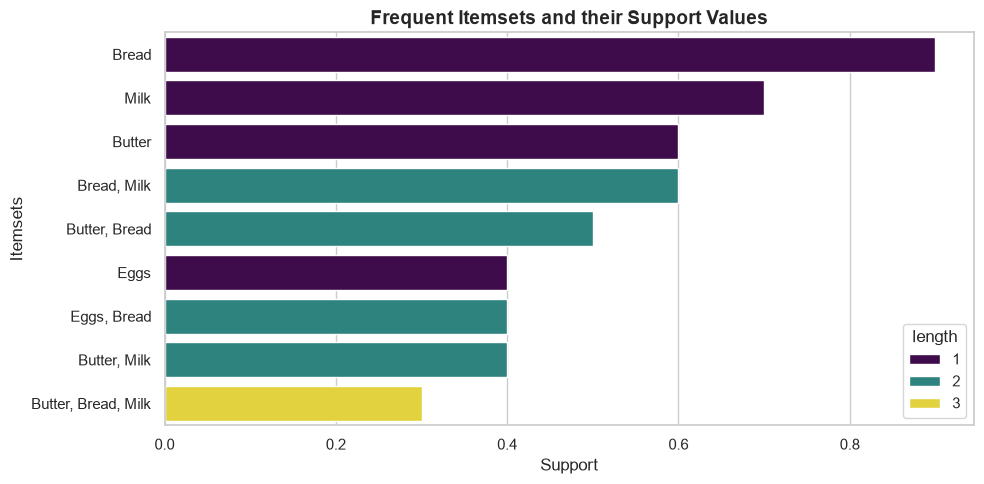

In [8]:
# 1. Bar Chart of Frequent Itemsets
plt.figure(figsize=(10, 5))
sorted_itemsets_for_plot = frequent_itemsets.sort_values(by='support', ascending=False)
sns.barplot(
    x=sorted_itemsets_for_plot['support'],
    y=sorted_itemsets_for_plot['itemsets'].apply(lambda x: ', '.join(list(x))),
    hue=sorted_itemsets_for_plot['length'],
    palette="viridis",
    legend=True
)
plt.title('Frequent Itemsets and their Support Values', fontsize=14, fontweight='bold')
plt.xlabel('Support', fontsize=12)
plt.ylabel('Itemsets', fontsize=12)
plt.tight_layout()
plt.show()

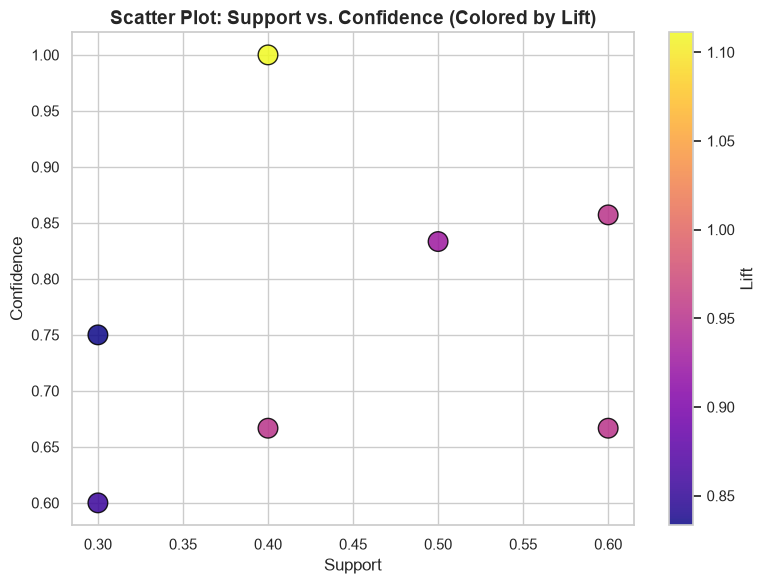

In [9]:
# 2. Scatter Plot of Support vs. Confidence vs. Lift
if not rules_display.empty:
    plt.figure(figsize=(8, 6))
    scatter = plt.scatter(
        rules_display['support'],
        rules_display['confidence'],
        c=rules_display['lift'],
        cmap='plasma',
        s=200,
        edgecolors='black',
        alpha=0.85
    )
    plt.colorbar(scatter, label='Lift')
    plt.title('Scatter Plot: Support vs. Confidence (Colored by Lift)', fontsize=14, fontweight='bold')
    plt.xlabel('Support', fontsize=12)
    plt.ylabel('Confidence', fontsize=12)
    plt.tight_layout()
    plt.show()
else:
    print("No rules available to generate Support vs. Confidence scatter plot.")

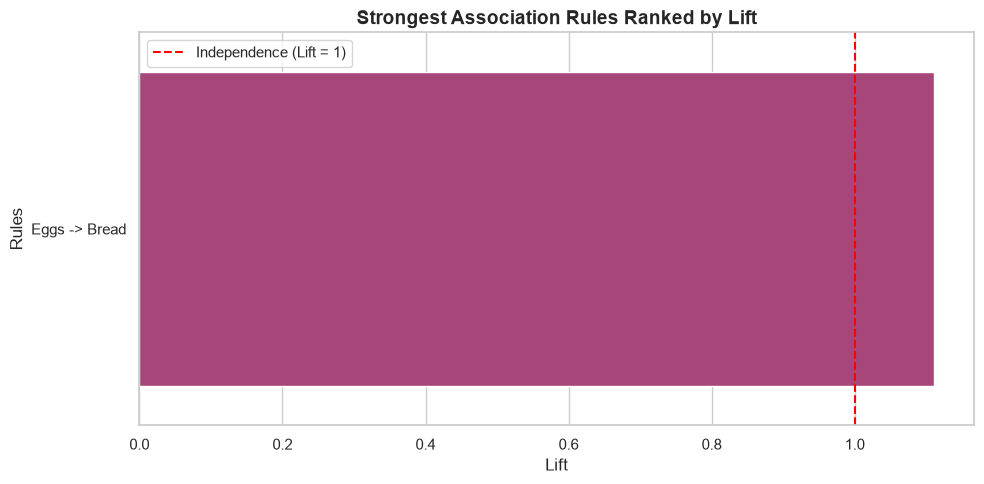

In [10]:
# 3. Bar Chart of the Strongest Association Rules Ranked by Lift
if not strong_rules.empty:
    plt.figure(figsize=(10, 5))
    # Create labels for rules: e.g., 'A -> B'
    strong_rules['rule_label'] = strong_rules['Antecedents'] + ' -> ' + strong_rules['Consequents']

    sns.barplot(
        x='lift',
        y='rule_label',
        data=strong_rules.sort_values(by='lift', ascending=False),
        palette='magma',
        hue='rule_label',
        legend=False
    )
    plt.title('Strongest Association Rules Ranked by Lift', fontsize=14, fontweight='bold')
    plt.xlabel('Lift', fontsize=12)
    plt.ylabel('Rules', fontsize=12)
    plt.axvline(x=1.0, color='red', linestyle='--', label='Independence (Lift = 1)')
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print("No strong rules available (Lift > 1) to generate ranking plot.")

## 9. Mathematical Concepts

### 1. Support
Measures how frequently an itemset appears in transactions.
$$\text{Support}(X) = \frac{\sigma(X)}{N}$$
- $\sigma(X)$: Frequency count of $X$.
- $N$: Total number of transactions in database.
- *Example*: Out of 10 transactions, 9 contain Bread. $\text{Support}(\text{Bread}) = 9 / 10 = 0.9$.

### 2. Confidence
Measures how often items in $Y$ appear in transactions that contain $X$.
$$\text{Confidence}(X \rightarrow Y) = \frac{\text{Support}(X \cup Y)}{\text{Support}(X)}$$
- *Example*: 6 transactions contain both Milk and Bread. 7 transactions contain Milk. $\text{Confidence}(\text{Milk} \rightarrow \text{Bread}) = 6 / 7 \approx 0.857$ (85.7%).

### 3. Lift
Measures the strength of a rule over random co-occurrence. It is the ratio of confidence to expected confidence.
$$\text{Lift}(X \rightarrow Y) = \frac{\text{Confidence}(X \rightarrow Y)}{\text{Support}(Y)} = \frac{\text{Support}(X \cup Y)}{\text{Support}(X) \times \text{Support}(Y)}$$
- **Lift > 1**: Positive correlation (items occur together more often than expected by chance).
- **Lift = 1**: Independence (occurrence of $X$ is independent of $Y$).
- **Lift < 1**: Negative correlation (purchase of $X$ decreases probability of purchasing $Y$).

### Core Terms:
- **Antecedent**: The left-hand side itemset (if bought...).
- **Consequent**: The right-hand side itemset (...then also likely to buy).
- **Apriori Property**: All non-empty subsets of a frequent itemset must also be frequent. If an itemset is infrequent, all its supersets will also be infrequent (Pruning Principle).

## 10. Results and Business Interpretation

### Findings Summary
- **High-frequency items**: Bread (90%) and Milk (70%) are in most baskets, followed by Butter (60%) and Eggs (40%).
- **Frequent combinations**: `{Milk, Bread}` is the most frequent pair (60% of baskets); `{Milk, Bread, Butter}` is the only frequent triple (30%).
- **Strongest rule**: `{Eggs} -> {Bread}` with 100% confidence and a lift of 1.11 - the only rule that passes both `confidence >= 0.60` and `lift > 1`.

### Business recommendations
1. **Cross-selling**: when Eggs are added to a cart, remind the shopper about Bread (every Eggs basket in the data also had Bread).
2. **Do not over-read confidence**: rules with Bread as the consequent have high confidence only because Bread is nearly universal; their lift is at or below 1, so promoting them adds little.
3. **Bundles**: a "Breakfast essentials" bundle of Bread, Milk and Butter is supported by the only frequent 3-itemset (30%).

## 11. Conclusion
In this lab, we successfully:
- Implemented the **Apriori algorithm** with python's `mlxtend` package.
- Transformed raw checkout data into a boolean / numerical one-hot matrix.
- Discovered frequent itemsets and computed **support, confidence and lift**.
- Showed that high confidence alone can mislead: of seven rules above 60% confidence, only `{Eggs} -> {Bread}` has lift greater than 1.
- Visualised the itemsets and rules with bar charts and a support-confidence-lift scatter plot.